borrar antes de entregar


In [2]:
import catalogo as cat
registro = cat.leer_satelites("datos/satelites.json")
print(registro[3000])
type(registro)

{'OBJECT_NAME': 'STARLINK-3647', 'OBJECT_ID': '2022-025AQ', 'EPOCH': '2026-10-27T06:40:20.638560', 'MEAN_MOTION': 15.34334896, 'ECCENTRICITY': 0.00013732, 'INCLINATION': 53.1599, 'RA_OF_ASC_NODE': 41.4557, 'ARG_OF_PERICENTER': 112.667, 'MEAN_ANOMALY': 247.4478, 'EPHEMERIS_TYPE': 0, 'CLASSIFICATION_TYPE': 'U', 'NORAD_CAT_ID': 51994, 'ELEMENT_SET_NO': 999, 'REV_AT_EPOCH': 25612, 'BSTAR': 0.00025683164, 'MEAN_MOTION_DOT': 8.293e-05, 'MEAN_MOTION_DDOT': 0}


list

In [3]:
cat.anio_lanzamiento(registro[1000])

2017

In [4]:
print(cat.grupo('ASTRA 2G'))
print(cat.grupo('STARLINK-3655'))


Otros
Starlink


In [5]:
cat.contar_por_grupo(registro)

{'Otros': 4152,
 'GPS': 40,
 'Globalstar': 36,
 'BeiDou': 55,
 'Iridium': 80,
 'OneWeb': 651,
 'Starlink': 11160,
 'Qianfan': 257,
 'Kuiper': 391}

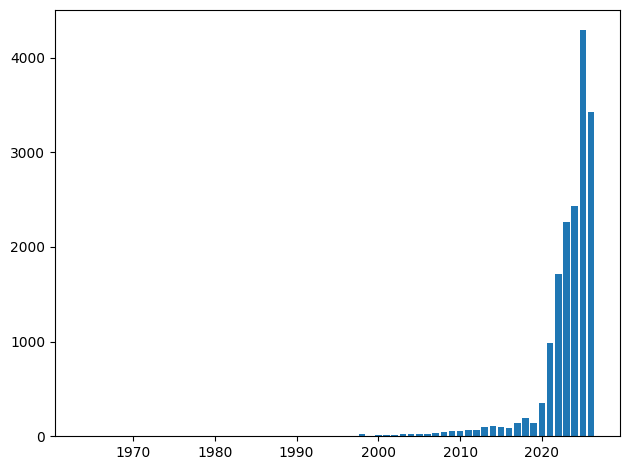

In [6]:
import matplotlib.pyplot as plt
datos = cat.lanzamientos_por_anio(registro)

categorias = list(datos.keys())
valores = list(datos.values())

barras = plt.bar(categorias, valores)

plt.tight_layout()
plt.show()


In [7]:
import analisis as an

an.ordenar_por

<function analisis.ordenar_por(satelites: list[satelite.Satelite], atributo: str, descendente: bool = False) -> list[satelite.Satelite]>

In [8]:
import satelite as sat
from analisis import ordenar_por

a = sat.Satelite("BETA", 10.0, 20.0, 500.0)
b = sat.Satelite("ALFA", -5.0, 30.0, 36000.0)
c = sat.Satelite("GAMA", 40.0, -60.0, 1200.0)
lista = [a, b, c]

print([s.nombre for s in ordenar_por(lista, "altitud_km")])
print([s.nombre for s in ordenar_por(lista, "altitud_km", descendente=True)])
print([s.nombre for s in ordenar_por(lista, "nombre")])
print([s.nombre for s in lista])

['BETA', 'GAMA', 'ALFA']
['ALFA', 'GAMA', 'BETA']
['ALFA', 'BETA', 'GAMA']
['BETA', 'ALFA', 'GAMA']


In [9]:
import analisis as an
print(an.resumen_por_grupo(lista))

{'Otros': {'cantidad': 3, 'minima': 500.0, 'media': 12566.666666666666, 'maxima': 36000.0}}


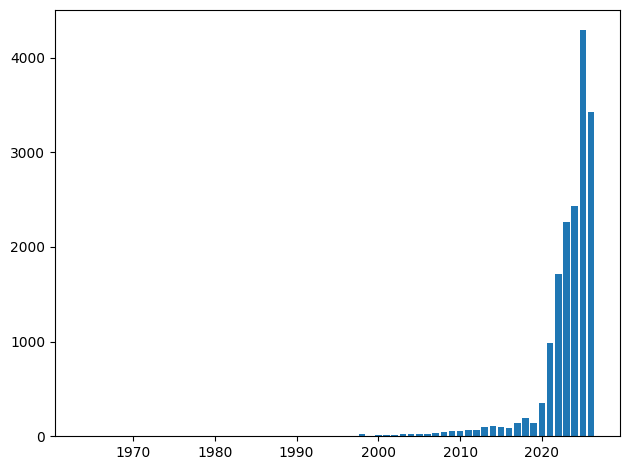

In [10]:
import matplotlib.pyplot as plt
datos = cat.lanzamientos_por_anio(registro)

categorias = list(datos.keys())
valores = list(datos.values())

barras = plt.bar(categorias, valores)

plt.tight_layout()
plt.show()

In [ ]:
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np

from catalogo import leer_satelites
from satelite import crear_satelites

registros = leer_satelites("datos/satelites.json")
ahora = datetime.now(timezone.utc)
satelites = crear_satelites(registros, ahora)

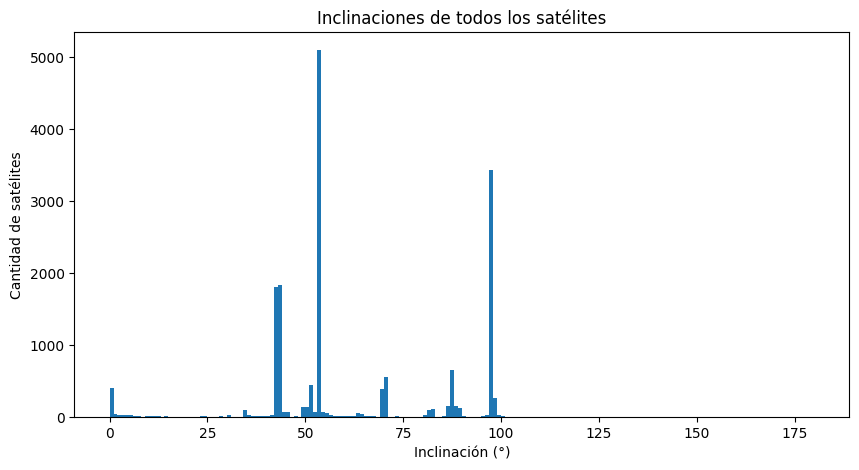

In [19]:
inclinaciones = [r["INCLINATION"] for r in registros]  # arma una lista con la inclinación de cada satélite
# for r in registros: recorre cada registro (diccionario) del JSON, y r es el registro actual
# r["INCLINATION"]: toma del registro el valor de la clave "INCLINATION" (en grados)

bins = np.arange(0, 181, 1)  # crea los bordes de los bins: 0, 1, 2, ..., 180
# se pone 181 y no 180 porque np.arange no incluye el último número, y queremos que llegue hasta 180
# el 1 final es el paso: cada bin mide 1°

plt.figure(figsize=(10, 5))  # crea una figura nueva de 10 de ancho por 5 de alto (pulgadas)
plt.hist(inclinaciones, bins=bins)  # dibuja el histograma: cuenta cuántos satélites caen en cada bin de 1°
plt.title("Inclinaciones de todos los satélites")  # título del gráfico
plt.xlabel("Inclinación (°)")  # texto del eje X
plt.ylabel("Cantidad de satélites")  # texto del eje Y
plt.show()  # muestra el gráfico en el notebook